# Research Methods for AI & Data Science: Experiment Design for ML

> **Who is this for:** MS/MPhil students and practitioners who need to show that a model, feature or idea *really* helps, in a way that convinces an examiner, a reviewer or a manager. Beginners welcome: every term is explained.
>
> **What you will learn:**
> - variables (independent, dependent, controlled, confounding); experiments vs observational studies; randomisation, blocking and factorial designs
> - ML protocols: train/validation/test discipline, nested CV, group- and time-aware splits, strong baselines, **ablation studies** (a real one, presented as a table), equal tuning budgets, **random seeds and variance**, learning curves and data-leakage traps
> - **power analysis**: how many test examples you need to detect a 1% accuracy difference (simulation + normal approximation)
> - threats to validity, benchmark overfitting and dataset shift
> - pre-registration, analysis plans, and human evaluation with **Cohen's kappa** and **Krippendorff's alpha** implemented from scratch
> - a reusable **experiment-plan template**
>
> **Prerequisites:** [01 – Research methodology](01_research_methodology_and_literature_review.ipynb), [model evaluation & cross-validation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb) (we build on its CV and nested-CV basics), and the hypothesis-testing parts of [Statistics for Data Science](../02_Data_Analysis/08_statistics.ipynb). The industry version of these ideas is in [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) and [model comparison & selection](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet (scikit-learn's built-in datasets + simulations). Full run: well under 3 minutes.
>
> **Optional track:** part of the university-level fundamentals track; recommended for BS/MS AI students, thesis students and interview prep.

### Table of contents
1. Variables, experiments and observational studies (with Simpson's paradox)
2. Randomisation, blocking and factorial designs
3. ML experiment protocols (splits, nested CV, groups, time, baselines, ablations, tuning budgets, seeds, learning curves, leakage)
4. Power analysis and sample size
5. Threats to validity, benchmark overfitting and dataset shift
6. Pre-registration, analysis plans and human evaluation (kappa, alpha)
7. An experiment-plan template
8. How this connects to modern AI, recap, practice problems, further reading

## Explained simply

An experiment is a fair test. If you want to know whether a new fertiliser helps tomatoes, you give both groups of plants the same sun, water and soil and change only the fertiliser; otherwise you cannot tell what caused the difference. Machine-learning experiments work the same way: same data split, same tuning effort and the same number of runs for every model. Luck plays a big role, because the same model trained twice can score differently, like a batsman who scores 80 one day and 20 the next, so you must run things several times. You also need enough test examples: judging two basketball players on 3 shots each tells you almost nothing. When people judge a model's answers, you check that the judges agree with each other, like two teachers marking the same essay. Planning all of this before you start keeps you honest.

**A tiny example.** Model A scores 85, 86 and 84 in three runs (average 85). Model B is run once and scores 87. Is B better? B is only 2 points above A's average, and A itself moved by 2 points between runs just by luck. So you cannot tell yet: run B a few more times with the same seeds before you claim anything.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Controlled experiment | change one thing, keep everything else the same | comparing two models on the same test set with the same budget |
| Random seed | the "dice roll" inside training | why the same model scores 85.1 one run and 86.3 the next |
| Power analysis | working out how many test examples you need to see a real difference | choosing a test-set size before a thesis or an A/B test |

In [1]:
import os                                           # limit numeric libraries to one CPU thread each:
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:   # small models run faster and more
    os.environ.setdefault(_v, "1")                  # reproducibly this way, even on a busy shared machine
import warnings                                     # to keep the output clean where we expect warnings
import tempfile, shutil                             # temporary folder for the experiment-plan file
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats                             # distributions (normal, binomial, chi-square)
import yaml                                         # PyYAML, to save the experiment plan

from sklearn.datasets import load_breast_cancer, load_digits, load_wine, make_classification
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, KFold,
                                     GroupKFold, TimeSeriesSplit, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, learning_curve)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import cohen_kappa_score, mean_absolute_error

SEED = 0                                            # one global seed; every split below derives from it
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 140)
T0 = time.time()                                    # to report the total runtime at the end
print("ready")

ready


## 1. Variables, experiments and observational studies

> **In plain English:** Change one thing on purpose, measure the result, and keep everything else fixed.

**Intuition.** Think of a cooking experiment: you want to know whether adding yoghurt makes a curry creamier. The yoghurt is what you *change*, creaminess is what you *measure*, the pot and the stove are what you *keep the same*, and if you always added yoghurt on days you used a better cut of meat, the meat would *confuse* your conclusion.

| Variable type | Definition | ML example |
|---|---|---|
| **Independent variable (IV, factor, treatment)** | what the researcher deliberately changes | model type, augmentation on/off, learning rate |
| **Dependent variable (DV, outcome, response)** | what is measured | accuracy, macro-F1, latency, human preference |
| **Controlled variable** | kept fixed so it cannot explain the result | same data split, same tuning budget, same hardware, same number of epochs |
| **Confounding variable (confounder)** | affects *both* the IV assignment and the DV, creating a fake (or hidden) effect | dataset difficulty when model A was only run on hard datasets |

**Controlled experiment vs observational study.**
- In a **controlled experiment** the researcher *assigns* the IV (ideally at random). Random assignment breaks the link between the IV and every confounder, known or unknown, so a difference in the DV can be read **causally**.
- In an **observational study** the researcher only *records* what happened (e.g. old experiment logs, papers' reported numbers, production data). Confounders may explain any difference; causal claims need extra assumptions (see [causal inference](../03_Machine_Learning/10_causal_inference/01_causal_inference.ipynb)).

### 1.1 Simpson's paradox in an experiment log

A team's log records how often two LLM-based assistants solved support questions. Nobody randomised: assistant A was mostly used for *hard* tickets. (The numbers mirror the famous kidney-stone study, Charig et al. 1986.)

In [2]:
log = pd.DataFrame({
    "assistant": ["A", "A", "B", "B"],
    "difficulty": ["easy", "hard", "easy", "hard"],
    "solved": [81, 192, 234, 55],
    "tickets": [87, 263, 270, 80],
})
log["solve_rate"] = (log.solved / log.tickets).round(3)
print(log.to_string(index=False))

overall = log.groupby("assistant")[["solved", "tickets"]].sum()        # ignore difficulty
overall["solve_rate"] = (overall.solved / overall.tickets).round(3)
print("\nIgnoring difficulty:\n", overall.to_string())

assistant difficulty  solved  tickets  solve_rate
        A       easy      81       87       0.931
        A       hard     192      263       0.730
        B       easy     234      270       0.867
        B       hard      55       80       0.688

Ignoring difficulty:
            solved  tickets  solve_rate
assistant                             
A             273      350       0.780
B             289      350       0.826


**What just happened?** Within *each* difficulty level, A is better (0.931 vs 0.867 on easy, 0.730 vs 0.688 on hard). But overall, B looks better (0.826 vs 0.780). This reversal is **Simpson's paradox**. The confounder is *difficulty*: it influenced which assistant was used (A got 263 of its 350 tickets from the hard pile) **and** the outcome (hard tickets are solved less often).

Now the fix: a **randomised experiment**. We send each new ticket to A or B by a coin flip, using the true per-difficulty solve rates from the log.

In [3]:
true_rate = {("A", "easy"): 0.931, ("A", "hard"): 0.730, ("B", "easy"): 0.867, ("B", "hard"): 0.688}
n_tickets = 4000
difficulty = rng.choice(["easy", "hard"], size=n_tickets, p=[0.5, 0.5])   # the incoming ticket mix
assistant = rng.choice(["A", "B"], size=n_tickets)                         # RANDOM assignment (coin flip)
p = np.array([true_rate[(a, d)] for a, d in zip(assistant, difficulty)])
solved = rng.random(n_tickets) < p                                          # simulate the outcome
rct = pd.DataFrame({"assistant": assistant, "difficulty": difficulty, "solved": solved})
print(rct.groupby("assistant").solved.mean().round(3).to_string())
print("share of hard tickets per assistant:", rct.groupby("assistant").difficulty.apply(lambda d: round((d == "hard").mean(), 3)).to_dict())

assistant
A    0.832
B    0.779
share of hard tickets per assistant: {'A': 0.499, 'B': 0.486}


**What just happened?** With random assignment both assistants get about the same share of hard tickets (0.499 and 0.486), so difficulty can no longer bias the comparison, and A's overall solve rate (0.832) is now correctly above B's (0.779). **Randomisation turns an observational comparison into a fair experiment.**

> ⚠️ **Common mistake:** comparing your model with numbers copied from other papers is an *observational* comparison: different preprocessing, splits, seeds and hardware are all potential confounders. Re-run baselines under your own protocol whenever you can.

## 2. Randomisation, blocking and factorial designs

> **In plain English:** Use coin flips to be fair, compare like with like, and test several changes together.

- **Randomisation:** assign treatments (or data splits, run order, seeds) at random so unknown confounders balance out on average.
- **Blocking:** group experimental units that are alike (a **block**) and compare treatments *within* each block. "Block what you can, randomise what you cannot" (Box, Hunter & Hunter). In ML the most important block is the **data split**: evaluate every model on the *same* folds and the *same* test set, then analyse **paired differences**.
- **Factorial design:** vary several factors *together* in all combinations. A 2×2×2 ("2³") design runs 8 configurations and estimates every **main effect** and every **interaction** (does factor A's effect depend on factor B?). Changing one factor at a time (OFAT) cannot see interactions.

### 2.1 Why blocking (pairing) matters

We compare logistic regression and Gaussian naive Bayes on the breast-cancer data over 30 random splits, analysed two ways: **unpaired** (each model evaluated on *different* random splits) and **paired** (both models on the *same* split, then take the difference).

In [4]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)                   # 569 tumours, 30 features
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
nbayes = GaussianNB()

def split_score(model, seed):
    Xtr, Xte, ytr, yte = train_test_split(X_bc, y_bc, test_size=0.3, random_state=seed, stratify=y_bc)
    return model.fit(Xtr, ytr).score(Xte, yte)

R = 30
lr_same = np.array([split_score(lr, s) for s in range(R)])               # seeds 0..29
nb_same = np.array([split_score(nbayes, s) for s in range(R)])           # SAME seeds -> paired
nb_other = np.array([split_score(nbayes, 100 + s) for s in range(R)])    # different seeds -> unpaired

paired_diff = lr_same - nb_same
unpaired_diff = lr_same - nb_other
print(f"mean difference (paired):   {paired_diff.mean():.4f}, std of differences {paired_diff.std(ddof=1):.4f}")
print(f"mean difference (unpaired): {unpaired_diff.mean():.4f}, std of differences {unpaired_diff.std(ddof=1):.4f}")
print(f"correlation of the two models' scores on the same split: {np.corrcoef(lr_same, nb_same)[0, 1]:.2f}")

mean difference (paired):   0.0380, std of differences 0.0178
mean difference (unpaired): 0.0396, std of differences 0.0198
correlation of the two models' scores on the same split: 0.38


**What just happened?** Both analyses estimate roughly the same mean gain for logistic regression (about 4 percentage points: 0.0380 paired, 0.0396 unpaired), but the **paired** differences are less noisy (std 0.0178 vs 0.0198). The reason is the positive correlation (0.38): an "easy" split is easy for both models, so taking the difference *within* the block cancels that shared noise. A smaller std means narrower confidence intervals and more power, for free. With more strongly correlated models (e.g. two variants of the same network) the gain is much larger. Notebook 3 builds every test on paired differences for this reason.

### 2.2 A real 2³ factorial experiment

Factors for a k-nearest-neighbours classifier: **scaling** (none / standard), **k** (1 / 15) and **weights** (uniform / distance). We run all 8 combinations on the same 5×4 repeated CV folds (blocking!) and estimate effects.

In [5]:
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)   # 20 shared folds
rows = []
for scale in [0, 1]:
    for k_level in [0, 1]:
        for w_level in [0, 1]:
            steps = ([StandardScaler()] if scale else []) + [
                KNeighborsClassifier(n_neighbors=[1, 15][k_level], weights=["uniform", "distance"][w_level])]
            acc = cross_val_score(make_pipeline(*steps), X_bc, y_bc, cv=cv_rep).mean()
            rows.append({"scaling": scale, "k15": k_level, "distance_w": w_level, "accuracy": acc})
fact = pd.DataFrame(rows)
print(fact.round(4).to_string(index=False))

def effect(df, *factors):
    # Effect = mean response when the product of +/-1 codes is +1 minus when it is -1 (standard 2^k contrast)
    sign = np.prod([2 * df[f] - 1 for f in factors], axis=0)
    return df.accuracy[sign == 1].mean() - df.accuracy[sign == -1].mean()

effects = {name: effect(fact, *f) for name, f in {
    "scaling": ["scaling"], "k (1->15)": ["k15"], "weights": ["distance_w"],
    "scaling x k": ["scaling", "k15"], "scaling x weights": ["scaling", "distance_w"],
    "k x weights": ["k15", "distance_w"], "scaling x k x weights": ["scaling", "k15", "distance_w"]}.items()}
print("\nEstimated effects on accuracy (percentage points):")
for k, v in effects.items():
    print(f"  {k:<24}{100 * v:+.2f}")

 scaling  k15  distance_w  accuracy
       0    0           0    0.9170
       0    0           1    0.9170
       0    1           0    0.9297
       0    1           1    0.9328
       1    0           0    0.9508
       1    0           1    0.9508
       1    1           0    0.9622
       1    1           1    0.9631

Estimated effects on accuracy (percentage points):
  scaling                 +3.26
  k (1->15)               +1.31
  weights                 +0.10
  scaling x k             -0.12
  scaling x weights       -0.05
  k x weights             +0.10
  scaling x k x weights   -0.05


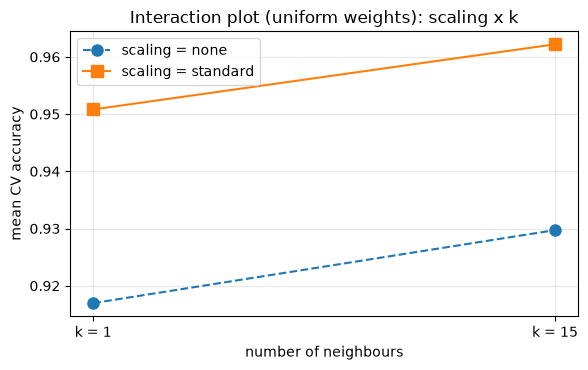

In [6]:
# Interaction plot: if the lines are not parallel, the two factors interact
fig, ax = plt.subplots(figsize=(6, 3.8))
for scale, style in [(0, "o--"), (1, "s-")]:
    sub = fact[fact.distance_w == 0].sort_values("k15")
    sub = sub[sub.scaling == scale]
    ax.plot(["k = 1", "k = 15"], sub.accuracy, style, label=f"scaling = {'standard' if scale else 'none'}", markersize=8)
ax.set_ylabel("mean CV accuracy"); ax.set_xlabel("number of neighbours")
ax.set_title("Interaction plot (uniform weights): scaling x k")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?** **Scaling** has by far the largest main effect (+3.26 points): kNN uses distances, and unscaled features with large ranges dominate them. Raising k from 1 to 15 also helps (+1.31), while the weighting scheme hardly matters (+0.10). All interactions are tiny (|effect| ≤ 0.12 points), and the interaction plot shows two almost **parallel** lines: k helps by about the same amount with scaling (0.951 → 0.962) and without it (0.917 → 0.930). That is a useful finding in itself: you can study k and scaling separately for this model. When lines are *not* parallel (an interaction), a one-factor-at-a-time study gives a different answer depending on where it starts, and only a factorial design reveals why.

**Cost:** a full 2^f factorial needs 2^f configurations × (number of folds) fits; for many factors, *fractional* factorial designs run a carefully chosen subset.

> 🎓 **Exam / interview tip:** "What is an interaction effect?" It is when the effect of one factor depends on the level of another. In a plot of the means, interactions show up as non-parallel lines.

## 3. ML experiment protocols

> **In plain English:** The everyday rules that make an ML comparison fair: clean splits, strong baselines, equal effort, several runs.

### 3.1 Train / validation / test discipline

```
  full data ──► split ONCE, before looking ──► TEST set (locked away; use at the very end, ideally once)
                    │
                    └──► DEVELOPMENT set ──► cross-validation or train/validation split
                                               (model selection, tuning, ablations, early stopping)
```

- **Training set:** fits the parameters.
- **Validation set** (or the inner CV folds): chooses hyper-parameters, features, architectures, epochs.
- **Test set:** estimates the performance of the *final, already chosen* model. Every time you look at the test score and then change something, the test set leaks into your choices and the estimate becomes optimistic (Section 5).

**Nested cross-validation** applies the same discipline when the data are too small for a fixed test set: an **inner** CV loop tunes hyper-parameters, an **outer** CV loop measures the performance *of the whole tuning procedure*. Reporting the best inner score (`GridSearchCV.best_score_`) instead is optimistic, because the maximum of many noisy scores is biased upwards. The basics are in [model evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb); here we *measure* the optimism on small, noisy datasets where it matters.

In [7]:
grid = {"kneighborsclassifier__n_neighbors": list(range(1, 31, 2)),               # 15 values of k
        "kneighborsclassifier__weights": ["uniform", "distance"]}                  # x 2 = 30 configurations
gaps = []
for trial in range(5):
    Xs, ys = make_classification(n_samples=120, n_features=20, n_informative=3, flip_y=0.15, random_state=trial)
    inner = StratifiedKFold(3, shuffle=True, random_state=trial)
    outer = StratifiedKFold(5, shuffle=True, random_state=100 + trial)
    search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), grid, cv=inner)
    non_nested = search.fit(Xs, ys).best_score_                                  # optimistic
    nested = cross_val_score(search, Xs, ys, cv=outer).mean()                    # honest
    gaps.append((non_nested, nested))
gaps = pd.DataFrame(gaps, columns=["non_nested", "nested"])
gaps["optimism"] = gaps.non_nested - gaps.nested
print(gaps.round(3).to_string())
print(f"\nmean optimism of the non-nested estimate: {gaps.optimism.mean():.3f} (positive in {(gaps.optimism > 0).sum()} of {len(gaps)} trials)")

   non_nested  nested  optimism
0       0.675   0.667     0.008
1       0.833   0.808     0.025
2       0.692   0.633     0.058
3       0.833   0.808     0.025
4       0.633   0.567     0.067

mean optimism of the non-nested estimate: 0.037 (positive in 5 of 5 trials)


**What just happened?** On 5 small (120-example), noisy datasets, the non-nested "best CV score" exceeded the nested estimate in every trial, by **0.037 accuracy on average** (up to 0.067). On large datasets with a small grid the gap shrinks, but you cannot know it is small without measuring it.

**Cost:** nested CV with K_outer outer folds, K_inner inner folds and G grid points needs about K_outer × (K_inner × G + 1) fits: here 5 × (3 × 30 + 1) = 455 fits per dataset, plus 3 × 30 = 90 for the non-nested search.

### 3.2 Group-aware and time-aware splits

The basic assumption of random K-fold CV is that rows are **independent**. Two common violations:

- **Grouped data:** several rows come from the same patient, user, speaker, document or camera. If the same patient appears in train and test, the model can recognise *the patient* instead of learning *the disease*. Use **GroupKFold** (all rows of a group stay on one side).
- **Temporal data:** the future must never be used to predict the past. Use **TimeSeriesSplit** (train on the past, test on the next block), or a single out-of-time test period.

In [8]:
# Grouped data: 40 patients x 10 scans. Each patient has a strong personal "signature" in the features,
# and a weak true disease signal. The label is per patient.
n_pat, per = 40, 10
pat_label = rng.permutation(np.repeat([0, 1], n_pat // 2))             # half the patients are ill
signature = rng.normal(0, 3, size=(n_pat, 8))                          # patient-specific offsets
groups = np.repeat(np.arange(n_pat), per)
y_g = pat_label[groups]
X_g = signature[groups] + rng.normal(0, 1, size=(n_pat * per, 8))     # repeated scans of the same person
X_g[:, 0] += 0.6 * y_g                                                 # the weak real disease signal

rf = RandomForestClassifier(n_estimators=50, random_state=SEED)
random_cv = cross_val_score(rf, X_g, y_g, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
group_cv = cross_val_score(rf, X_g, y_g, cv=GroupKFold(5), groups=groups).mean()
print(f"random KFold accuracy: {random_cv:.3f}   <- patients leak across folds")
print(f"GroupKFold accuracy:   {group_cv:.3f}   <- honest estimate for NEW patients")

random KFold accuracy: 0.938   <- patients leak across folds
GroupKFold accuracy:   0.507   <- honest estimate for NEW patients


In [9]:
# Temporal data: a random walk (e.g. daily demand). Feature = the day index only.
n_days = 500
series = np.cumsum(rng.normal(0, 1, n_days))                           # tomorrow = today + noise
X_t = np.arange(n_days).reshape(-1, 1)
rfr = RandomForestRegressor(n_estimators=50, random_state=SEED)
mae_shuffled = -cross_val_score(rfr, X_t, series, cv=KFold(5, shuffle=True, random_state=SEED),
                                scoring="neg_mean_absolute_error").mean()
mae_time = -cross_val_score(rfr, X_t, series, cv=TimeSeriesSplit(5),
                            scoring="neg_mean_absolute_error").mean()
print(f"shuffled KFold MAE:   {mae_shuffled:.2f}   <- interpolates between known neighbouring days")
print(f"TimeSeriesSplit MAE: {mae_time:.2f}   <- has to forecast the unseen future")

shuffled KFold MAE:   0.69   <- interpolates between known neighbouring days
TimeSeriesSplit MAE: 5.35   <- has to forecast the unseen future


**What just happened?**
- **Groups:** random K-fold reports 0.938 accuracy because almost every test scan has sibling scans from the same patient in training, and the patient's signature gives the label away. GroupKFold reports 0.507 for *new* patients (about chance: with 40 patients the weak disease signal is not learnable), which is the number that matters clinically. The gap (0.94 vs 0.51) is entirely leakage.
- **Time:** with shuffled folds the forest sees days 99 and 101 when predicting day 100, so the error is tiny (MAE 0.69); forecasting the next block of days honestly gives MAE 5.35, almost 8 times larger.

> ⚠️ **Common mistake:** splitting *sentences* randomly when several sentences come from the same document, or *frames* when several frames come from the same video. Split by the highest-level unit you want to generalise to (document, video, speaker, hospital).

### 3.3 Strong baselines

A result is only as convincing as the baseline it beats. Include three kinds:

| Baseline | Purpose | Examples |
|---|---|---|
| **Trivial** | the floor: is the problem even learnable? Catches bugs and class imbalance | majority class, stratified random guess, "predict yesterday's value", copy the input |
| **Classical / simple** | is the complex method worth its cost? | TF-IDF + logistic regression, random forest, gradient boosting, BM25 |
| **Prior state of the art** | is it actually *new*? | the best published method, **re-run under your protocol** (same split, budget, seeds) |

In [10]:
baselines = {
    "trivial: majority class": DummyClassifier(strategy="most_frequent"),
    "trivial: stratified guess": DummyClassifier(strategy="stratified", random_state=SEED),
    "classical: logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "classical: random forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "strong: gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}
cv5x3 = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
base_rows = []
for name, model in baselines.items():
    s = cross_val_score(model, X_bc, y_bc, cv=cv5x3)
    base_rows.append({"baseline": name, "accuracy mean": s.mean(), "std over 10 folds": s.std(ddof=1)})
print(pd.DataFrame(base_rows).round(3).to_string(index=False))

                      baseline  accuracy mean  std over 10 folds
       trivial: majority class          0.627              0.004
     trivial: stratified guess          0.548              0.018
classical: logistic regression          0.975              0.019
      classical: random forest          0.962              0.014
     strong: gradient boosting          0.968              0.010


**What just happened?** On the breast-cancer data the majority class already scores 0.627 (62.7% of tumours are benign), so "90% accuracy" would be much less impressive than it sounds. A plain scaled logistic regression reaches 0.975, slightly *above* the random forest (0.962) and gradient boosting (0.968). A new method claiming 0.97 here would be *no better than the simplest classical baseline*. Always report the trivial and simple baselines.

### 3.4 Ablation studies

An **ablation study** removes (or replaces) one component at a time and measures the drop, to show *which parts of the system cause the gain*. Reviewers almost always ask for one.

The breast-cancer features come in three natural **groups** of 10: the **mean**, the **standard error** and the **worst** (largest) value of each cell-nucleus measurement. We ablate each group inside a scikit-learn pipeline, on the same 50 folds (5 × 10 repeated CV), and report each configuration with the paired difference from the full model.

In [11]:
names = load_breast_cancer().feature_names
groups_idx = {
    "mean":  [i for i, n in enumerate(names) if n.startswith("mean ")],
    "error": [i for i, n in enumerate(names) if n.endswith(" error")],
    "worst": [i for i, n in enumerate(names) if n.startswith("worst ")],
}
assert sum(len(v) for v in groups_idx.values()) == 30                 # every feature is in exactly one group

def make_model(keep):
    # ColumnTransformer keeps only the chosen feature groups; everything else in the pipeline is identical
    cols = sorted(i for g in keep for i in groups_idx[g])
    select = ColumnTransformer([("keep", "passthrough", cols)])
    return Pipeline([("select", select), ("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))])

configs = {
    "full model (all 3 groups)": ["mean", "error", "worst"],
    "- mean": ["error", "worst"],
    "- error": ["mean", "worst"],
    "- worst": ["mean", "error"],
    "only mean": ["mean"],
    "only error": ["error"],
    "only worst": ["worst"],
}
cv_abl = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)   # 50 shared folds = blocking
fold_scores = {name: cross_val_score(make_model(keep), X_bc, y_bc, cv=cv_abl) for name, keep in configs.items()}

full = fold_scores["full model (all 3 groups)"]
abl = pd.DataFrame({
    "configuration": list(configs),
    "n features": [10 * len(k) for k in configs.values()],
    "accuracy (mean ± std)": [f"{s.mean():.3f} ± {s.std(ddof=1):.3f}" for s in fold_scores.values()],
    "Δ vs full (points)": [f"{100 * (s - full).mean():+.2f}" for s in fold_scores.values()],
    "folds worse / better than full": [f"{(s < full).sum()} / {(s > full).sum()}" for s in fold_scores.values()],
})
print(abl.to_string(index=False))

            configuration  n features accuracy (mean ± std) Δ vs full (points) folds worse / better than full
full model (all 3 groups)          30         0.977 ± 0.015              +0.00                          0 / 0
                   - mean          20         0.978 ± 0.013              +0.03                        15 / 18
                  - error          20         0.977 ± 0.015              -0.02                        17 / 14
                  - worst          20         0.954 ± 0.021              -2.32                         44 / 4
                only mean          10         0.938 ± 0.023              -3.94                         49 / 0
               only error          10         0.874 ± 0.026             -10.33                         50 / 0
               only worst          10         0.977 ± 0.013              -0.02                        19 / 17


**What just happened?** The table is the standard way to present an ablation:

- Removing the **worst** group costs the most (−2.32 points; worse on 44 of 50 folds, better on only 4). Using *only* the worst group gives 0.977, the same as the full model.
- Removing **mean** or **error** changes nothing measurable (+0.03 and −0.02 points, with wins and losses split roughly evenly across folds), and "only error" (0.874) is clearly the weakest group.

This also teaches the main trap of ablations: **redundancy**. The "mean" features look useless when removed, yet "only mean" scores 0.938, far above the majority baseline. They are informative, but the "worst" features already carry the same information. Removing one component tells you about its *unique* contribution, not its total usefulness. Report both directions ("−X" and "only X") when components overlap.

Whether a −2.32 point drop is *statistically* real is a question for notebook 3 (corrected resampled t-test on these paired fold differences).

**Cost:** C configurations × F folds fits (here 7 × 50 = 350 small fits).

### 3.5 Hyper-parameter tuning fairness

A classic way to inflate gains, often unintentionally: tune *your* method carefully and run the baselines with default settings. The fair protocol gives **every method the same tuning budget** (same number of trials, same search space quality, same validation data). We compare kNN and an RBF SVM on the wine data with nested CV.

In [12]:
X_w, y_w = load_wine(return_X_y=True)
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)                 # outer loop: honest estimate
inner = StratifiedKFold(3, shuffle=True, random_state=SEED + 1)             # inner loop: tuning
BUDGET = 20                                                                 # trials per method

knn_space = {"scale": [StandardScaler(), MinMaxScaler(), "passthrough"],
             "clf__n_neighbors": stats.randint(1, 31), "clf__weights": ["uniform", "distance"]}
svc_space = {"scale": [StandardScaler(), MinMaxScaler(), "passthrough"],
             "clf__C": stats.loguniform(1e-2, 1e3), "clf__gamma": stats.loguniform(1e-4, 1e0)}
knn_pipe = Pipeline([("scale", "passthrough"), ("clf", KNeighborsClassifier())])   # default: no scaling, k=5
svc_pipe = Pipeline([("scale", "passthrough"), ("clf", SVC())])

def tuned(pipe, space):
    return RandomizedSearchCV(pipe, space, n_iter=BUDGET, cv=inner, random_state=SEED)

res = {
    "kNN, default settings": cross_val_score(knn_pipe, X_w, y_w, cv=outer).mean(),
    f"kNN, tuned ({BUDGET} trials)": cross_val_score(tuned(knn_pipe, knn_space), X_w, y_w, cv=outer).mean(),
    f"SVM, tuned ({BUDGET} trials)": cross_val_score(tuned(svc_pipe, svc_space), X_w, y_w, cv=outer).mean(),
}
for k, v in res.items():
    print(f"{k:<26}{v:.3f}")
unfair = res[f"SVM, tuned ({BUDGET} trials)"] - res["kNN, default settings"]
fair = res[f"SVM, tuned ({BUDGET} trials)"] - res[f"kNN, tuned ({BUDGET} trials)"]
print(f"\n'Improvement' of SVM, unfair comparison: {100 * unfair:+.1f} points")
print(f"Improvement of SVM, equal budget:        {100 * fair:+.1f} points")

kNN, default settings     0.663
kNN, tuned (20 trials)    0.978
SVM, tuned (20 trials)    0.972

'Improvement' of SVM, unfair comparison: +30.9 points
Improvement of SVM, equal budget:        -0.6 points


**What just happened?** Against a default kNN (0.663, no feature scaling), the tuned SVM (0.972) looks like a **+30.9 point** breakthrough. Given the same 20-trial budget (which lets it discover scaling), kNN reaches 0.978 and the SVM's advantage disappears completely (**−0.6 points**: the tuned kNN is even slightly ahead). This pattern (big published gains that shrink or vanish under equal tuning) has been documented for neural recommenders, GAN variants, deep metric learning and language-model training tricks.

**Rules:** same search budget (trials or GPU-hours), search spaces of comparable quality, same validation data, report the budget, and tune baselines from the original papers' recommended ranges. See [hyper-parameter optimisation](../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb) for search methods.

### 3.6 Random seeds and variance

Training involves randomness: weight initialisation, data shuffling, dropout, and the data split itself. A single run is **one sample** from a distribution of possible results. We train the same small neural network on the digits data with **10 seeds** in two settings: (a) fixed split, only the training seed changes; (b) the seed changes the split too.

init seed only     mean 0.9752  std 0.0063  min 0.9685  max 0.9870  range 1.85 points
init + split seed  mean 0.9752  std 0.0050  min 0.9667  max 0.9815  range 1.48 points


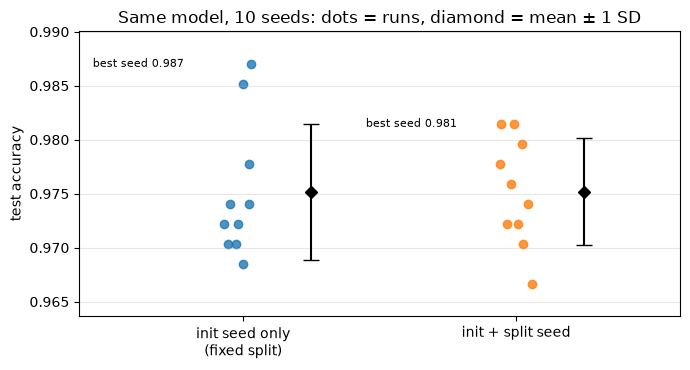

In [13]:
X_d, y_d = load_digits(return_X_y=True)                     # 1,797 8x8 images of digits 0-9

def mlp(seed):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32,), learning_rate_init=0.01,
                                                         max_iter=60, random_state=seed))
Xtr, Xte, ytr, yte = train_test_split(X_d, y_d, test_size=0.3, random_state=SEED, stratify=y_d)
seeds = range(10)
acc_init = []                                                # (a) only the model seed varies
acc_split = []                                               # (b) seed also changes the split
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                          # MLP may warn about convergence at 60 epochs
    for s in seeds:
        acc_init.append(mlp(s).fit(Xtr, ytr).score(Xte, yte))
        Xa, Xb, ya, yb = train_test_split(X_d, y_d, test_size=0.3, random_state=s, stratify=y_d)
        acc_split.append(mlp(s).fit(Xa, ya).score(Xb, yb))
acc_init, acc_split = np.array(acc_init), np.array(acc_split)
for name, a in [("init seed only", acc_init), ("init + split seed", acc_split)]:
    print(f"{name:<18} mean {a.mean():.4f}  std {a.std(ddof=1):.4f}  min {a.min():.4f}  max {a.max():.4f}  range {100 * (a.max() - a.min()):.2f} points")

fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (name, a) in enumerate([("init seed only\n(fixed split)", acc_init), ("init + split seed", acc_split)]):
    jitter = rng.uniform(-0.08, 0.08, len(a))
    ax.scatter(i + jitter, a, alpha=0.8, label=None)
    ax.errorbar(i + 0.25, a.mean(), yerr=a.std(ddof=1), fmt="D", color="black", capsize=6)
    ax.annotate(f"best seed {a.max():.3f}", (i, a.max()), xytext=(i - 0.55, a.max()), fontsize=8, va="center")
ax.set_xticks([0, 1], ["init seed only\n(fixed split)", "init + split seed"])
ax.set_ylabel("test accuracy"); ax.set_xlim(-0.6, 1.6)
ax.set_ylim(min(acc_init.min(), acc_split.min()) - 0.003, max(acc_init.max(), acc_split.max()) + 0.003)
ax.set_title("Same model, 10 seeds: dots = runs, diamond = mean ± 1 SD")
ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

**What just happened?** The *same* code and data produced test accuracies from 0.969 to 0.987 just by changing the initialisation seed (a range of 1.85 points, std 0.0063), and from 0.967 to 0.982 when the split changes too (1.48 points, std 0.0050). If a paper reports a +1 point gain from a single run, the gain is smaller than the seed noise.

**Rules for seeds:**
1. Run **at least 3–5 seeds** (10+ if cheap) for every method, *including baselines*, and report mean and spread (notebook 3 shows how).
2. Fix the seed list **before** the experiment (e.g. 0–9) and report all of them. Picking the best seed is cherry-picking.
3. Vary the sources of randomness that matter for your claim (initialisation, data order, split).

### 3.7 Learning curves

A **learning curve** plots performance against training-set size. It answers: *will more data help?* and *does the ranking of methods depend on data size?*

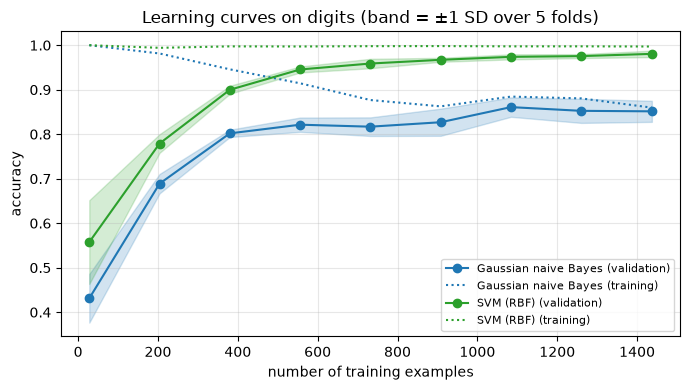

      Gaussian naive Bayes  SVM (RBF)
28                   0.431      0.558
204                  0.689      0.779
380                  0.802      0.900
556                  0.821      0.945
732                  0.817      0.959
908                  0.827      0.967
1084                 0.861      0.974
1260                 0.853      0.976
1437                 0.851      0.981


In [14]:
sizes = np.linspace(0.02, 1.0, 9)
fig, ax = plt.subplots(figsize=(7, 4))
curves = {}
for name, model in [("Gaussian naive Bayes", GaussianNB()),
                    ("SVM (RBF)", make_pipeline(StandardScaler(), SVC()))]:
    n_tr, tr_sc, va_sc = learning_curve(model, X_d, y_d, train_sizes=sizes,
                                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    curves[name] = pd.Series(va_sc.mean(1), index=n_tr)
    col = "tab:blue" if name.startswith("Gaussian") else "tab:green"          # one colour per model
    ax.plot(n_tr, va_sc.mean(1), "o-", color=col, label=f"{name} (validation)")
    ax.fill_between(n_tr, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color=col, alpha=0.2)
    ax.plot(n_tr, tr_sc.mean(1), ":", color=col, label=f"{name} (training)")
ax.set_xlabel("number of training examples"); ax.set_ylabel("accuracy")
ax.set_title("Learning curves on digits (band = ±1 SD over 5 folds)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(pd.DataFrame(curves).round(3).to_string())

**What just happened?** The SVM is ahead at every size, but the *shape* of the curves tells the story: naive Bayes climbs quickly and then plateaus around 0.82–0.86 from about 550 images on, while the SVM keeps improving (0.558 with 28 images, 0.945 with 556, 0.981 with 1,437) and its validation curve is still rising slowly. Two lessons: (1) a curve that is still rising says more data would help, while a flat curve well below the training score (naive Bayes: training ≈ 0.86–0.88, validation ≈ 0.85) points to a model limitation (high bias), so more data will not fix it; (2) the gap between methods depends on the data size (here 0.127 at 28 images, 0.18 at 380, 0.13 at 1,437), and on other problems curves can even cross, so state the training-set size with every conclusion.

### 3.8 Data-leakage traps

**Data leakage** means information that would not be available at prediction time influences training or model selection. It makes results look better than they will be in reality.

| Trap | Example | Fix |
|---|---|---|
| preprocessing on all data | scaler / imputer / feature selection fitted before the split | put every step in a `Pipeline`, fit inside each fold |
| duplicates across splits | near-identical images or texts in train and test | de-duplicate (hashing, MinHash) before splitting |
| group leakage | same patient/user/speaker in train and test | `GroupKFold` (Section 3.2) |
| temporal leakage | future data in training, or features computed with future values | time-based splits, point-in-time features |
| target leakage | a feature that is a consequence of the label ("discharge diagnosis code" to predict diagnosis) | ask "would I have this value at prediction time?" |
| test-set tuning | choosing epochs/thresholds/seeds on the test set | use a validation set; touch the test set once |
| pre-training contamination | LLM pre-training data contains the benchmark test set | check n-gram overlap, use post-cutoff or private test sets |

The most famous trap: **feature selection before cross-validation**. Here the features are *pure noise*, so the true accuracy is 50%.

In [15]:
X_noise = rng.normal(size=(100, 5000))                        # 100 examples, 5,000 random features
y_noise = rng.integers(0, 2, 100)                             # random labels: nothing to learn
cv_noise = StratifiedKFold(5, shuffle=True, random_state=SEED)

# WRONG: pick the 20 features most correlated with y using ALL data, then cross-validate
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv_noise).mean()

# RIGHT: selection is part of the pipeline, so it is re-fitted on the training part of each fold
right_pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(right_pipe, X_noise, y_noise, cv=cv_noise).mean()
print(f"selection BEFORE CV (leaky):   {wrong:.3f}")
print(f"selection INSIDE CV (correct): {right:.3f}   (true accuracy is 0.5)")

selection BEFORE CV (leaky):   0.820
selection INSIDE CV (correct): 0.400   (true accuracy is 0.5)


**What just happened?** On pure noise the leaky protocol reports **0.820** accuracy, while the correct pipeline reports 0.400, which is just the chance level 0.5 plus fold-to-fold noise on 100 examples. Out of 5,000 random features, some correlate with the labels *by chance in this sample*; selecting them using the test folds lets the test labels leak into the model. This exact mistake was found in published genomics papers (Ambroise & McLachlan, 2002).

## 4. Power analysis: how many test examples do I need?

> **In plain English:** Small test sets cannot see small improvements; this section tells you how big is big enough.

**Intuition.** A test set is a sample. A small test set is like judging two archers on three arrows each: the better archer often loses by luck. **Power analysis** tells you how big the test set must be so that a real difference of a given size is *likely to be detected*.

**Definitions.**
- **α (significance level):** the probability of a **false positive** (claiming a difference when there is none), usually 0.05.
- **Power = 1 − β:** the probability of detecting a difference that *really exists*, usually 0.80 (β = 0.20 is the false-negative rate).
- **Effect size δ:** the smallest difference you care about, here **1 percentage point of accuracy** (e.g. 0.85 vs 0.86).

### 4.1 Normal approximation, two designs

**(a) Independent test sets** (each model evaluated on a *different* random sample, e.g. an online A/B test): the two-proportion formula

$$n_{\text{per model}} = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \,[p_1(1-p_1) + p_2(1-p_2)]}{\delta^2}$$

**(b) Paired: both models on the same test set** (the normal case in ML). Only the examples where the models **disagree** carry information. Let ψ be the proportion of discordant examples (A right & B wrong, or A wrong & B right). McNemar's test needs about (Connor, 1987)

$$n = \frac{\left(z_{1-\alpha/2}\sqrt{\psi} + z_{1-\beta}\sqrt{\psi - \delta^2}\right)^2}{\delta^2}$$

Worked example for (a) by hand with p₁ = 0.85, p₂ = 0.86, z₀.₉₇₅ = 1.960, z₀.₈₀ = 0.842: numerator = (2.802)² × (0.1275 + 0.1204) = 7.849 × 0.2479 = 1.946; divide by δ² = 0.0001 → **≈ 19,460 examples per model**.

In [16]:
alpha, power = 0.05, 0.80
z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)        # 1.960 and 0.842
p1, p2 = 0.85, 0.86
delta = p2 - p1

def n_independent(p1, p2, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za + zb) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p2 - p1) ** 2))

def n_paired_mcnemar(delta, psi, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za * np.sqrt(psi) + zb * np.sqrt(psi - delta ** 2)) ** 2 / delta ** 2))

n_ind = n_independent(p1, p2)
print(f"(a) independent test sets: n = {n_ind:,} per model")
for psi in [0.03, 0.05, 0.10, 0.20]:
    print(f"(b) same test set, discordance psi = {psi:.2f}: n = {n_paired_mcnemar(delta, psi):,}")

# Optional cross-check with statsmodels (it uses Cohen's arcsine effect size h, so it differs slightly)
try:
    from statsmodels.stats.power import NormalIndPower
    from statsmodels.stats.proportion import proportion_effectsize
    h = proportion_effectsize(p2, p1)
    n_sm = NormalIndPower().solve_power(effect_size=h, alpha=alpha, power=power, alternative="two-sided")
    print(f"statsmodels (arcsine approximation): n = {np.ceil(n_sm):,.0f} per model")
except ImportError:
    print("statsmodels not installed; skipping the optional cross-check")

(a) independent test sets: n = 19,458 per model
(b) same test set, discordance psi = 0.03: n = 2,353
(b) same test set, discordance psi = 0.05: n = 3,923
(b) same test set, discordance psi = 0.10: n = 7,847
(b) same test set, discordance psi = 0.20: n = 15,696
statsmodels (arcsine approximation): n = 19,456 per model


**What just happened?** Detecting 85% vs 86% with independent samples needs **19,458 examples per model** (our hand calculation gave ≈ 19,460; the difference is rounding of z). statsmodels' arcsine approximation agrees (19,456). On a **shared test set** the requirement depends on how often the models disagree: if they disagree on 5% of examples, about **3,923** examples suffice; if they disagree on 20%, about **15,696**. Pairing helps most when the models are similar, which is exactly when the difference is small.

Formulas are approximations. Let's **simulate** to check them: generate many test sets, run McNemar's test on each, count how often it detects the difference.

 test examples  power, same test set (psi=0.05)  power, independent sets
           500                            0.113                    0.075
          1000                            0.246                    0.091
          2000                            0.479                    0.147
          4000                            0.796                    0.252
          8000                            0.974                    0.433
         16000                            1.000                    0.719
         32000                            1.000                    0.952

simulated power at the formula's n: paired n=3,923 -> 0.776; independent n=19,458 -> 0.798


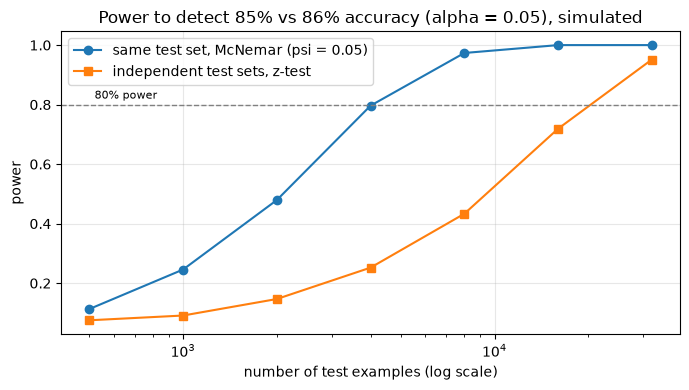

In [17]:
def simulate_power_mcnemar(n, p10, p01, reps=4000, alpha=0.05, rng=rng):
    # p10 = P(A right, B wrong), p01 = P(A wrong, B right); B is better by p01 - p10
    counts = rng.multinomial(n, [p10, p01, 1 - p10 - p01], size=reps)   # simulate many test sets at once
    b, c = counts[:, 0], counts[:, 1]
    with np.errstate(divide="ignore", invalid="ignore"):
        chi2 = np.where(b + c > 0, (np.abs(b - c) - 1.0) ** 2 / (b + c), 0.0)   # McNemar with continuity correction
    return (stats.chi2.sf(chi2, df=1) < alpha).mean()

def simulate_power_independent(n, p1, p2, reps=4000, alpha=0.05, rng=rng):
    a = rng.binomial(n, p1, reps) / n                                   # accuracy of model 1 on its own test set
    b = rng.binomial(n, p2, reps) / n
    pooled = (a + b) / 2
    z = (b - a) / np.sqrt(2 * pooled * (1 - pooled) / n)
    return (2 * stats.norm.sf(np.abs(z)) < alpha).mean()

psi = 0.05
p01, p10 = (psi + delta) / 2, (psi - delta) / 2                          # 0.03 and 0.02
n_formula = n_paired_mcnemar(delta, psi)
grid_n = [500, 1000, 2000, 4000, 8000, 16000, 32000]
pow_paired = [simulate_power_mcnemar(n, p10, p01) for n in grid_n]
pow_indep = [simulate_power_independent(n, p1, p2) for n in grid_n]
print(pd.DataFrame({"test examples": grid_n, "power, same test set (psi=0.05)": pow_paired,
                    "power, independent sets": pow_indep}).round(3).to_string(index=False))
print(f"\nsimulated power at the formula's n: paired n={n_formula:,} -> {simulate_power_mcnemar(n_formula, p10, p01, reps=20000):.3f}; "
      f"independent n={n_ind:,} -> {simulate_power_independent(n_ind, p1, p2, reps=20000):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid_n, pow_paired, "o-", label="same test set, McNemar (psi = 0.05)")
ax.plot(grid_n, pow_indep, "s-", label="independent test sets, z-test")
ax.axhline(0.8, color="gray", ls="--", lw=1); ax.text(520, 0.82, "80% power", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of test examples (log scale)"); ax.set_ylabel("power")
ax.set_title("Power to detect 85% vs 86% accuracy (alpha = 0.05), simulated")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?** The simulation confirms the formulas: at the formula's sample sizes the simulated power is close to 0.80 (0.776 paired, slightly below because the continuity-corrected test is a little conservative; 0.798 independent). The curves show how hopeless small test sets are for 1-point differences: with **1,000 test examples** the paired design detects the difference only about 25% of the time, and the independent design about 9% (barely above the 5% false-positive rate).

**The reverse question** is often more useful: *given my test set, what is the smallest difference I can reliably detect?* (the **minimum detectable effect**).

In [18]:
def mde_paired(n, psi, alpha=0.05, power=0.80):
    # smallest delta with n_paired_mcnemar(delta, psi) <= n, found by bisection
    lo, hi = 1e-5, psi
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if n_paired_mcnemar(mid, psi, alpha, power) <= n else (mid, hi)
    return hi

for n in [500, 1000, 2000, 5000, 10000]:
    print(f"n = {n:>6,}: MDE independent ≈ {100 * (z_a + z_b) * np.sqrt(2 * 0.855 * 0.145 / n):.1f} points; "
          f"same test set (psi=0.05) ≈ {100 * mde_paired(n, 0.05):.1f} points")

n =    500: MDE independent ≈ 6.2 points; same test set (psi=0.05) ≈ 2.8 points
n =  1,000: MDE independent ≈ 4.4 points; same test set (psi=0.05) ≈ 2.0 points


n =  2,000: MDE independent ≈ 3.1 points; same test set (psi=0.05) ≈ 1.4 points
n =  5,000: MDE independent ≈ 2.0 points; same test set (psi=0.05) ≈ 0.9 points


n = 10,000: MDE independent ≈ 1.4 points; same test set (psi=0.05) ≈ 0.6 points


**What just happened?** With 1,000 test examples and models that disagree on 5% of them, you can reliably detect only about a **2 point** difference (≈ 4.4 points with independent test sets); for 1 point you need roughly 4,000–5,000 (at n = 5,000 the MDE is 0.9 points). Write this into your proposal: "With n = 1,000 test items we have 80% power to detect differences of ≥ 2 points; smaller differences will be reported as inconclusive."

**Complexity:** the formulas are O(1); the simulation costs O(R × |grid|) random draws (fully vectorised in numpy).

## 5. Threats to validity

> **In plain English:** List every way your conclusion could be wrong, before a reviewer does it for you.

**Validity** is the degree to which your conclusions are justified. Cook & Campbell's classic four types, with ML examples:

| Threat | Question | ML examples | Mitigation |
|---|---|---|---|
| **Internal validity** | Did *my intervention* cause the difference? | unequal tuning budgets, leakage, different preprocessing, bugs in the baseline | controlled comparisons, ablations, same pipeline, code review |
| **External validity** | Does it *generalise* to other data, languages, users, time? | one dataset, one language, one domain; test set from the same crawl as training | multiple datasets, out-of-domain and out-of-time tests, state the scope |
| **Construct validity** | Do my measures capture *what I claim*? | BLEU used as "translation quality"; accuracy on multiple-choice used as "reasoning"; LLM-judge scores used as "helpfulness" | human evaluation, multiple metrics, validate metrics against humans |
| **Statistical conclusion validity** | Is the statistical inference sound? | single run, tiny test set, many uncorrected tests, wrong test for correlated folds | power analysis, seeds, proper tests (notebook 3), multiple-comparison correction |

### 5.1 Benchmark overfitting and test-set reuse

When a whole community (or one student over many months) evaluates hundreds of ideas on the **same public test set** and keeps the best, the test set is effectively used for model selection. The winner's score is biased upwards. Simulation: 500 "models" that guess at random (true accuracy 0.50), evaluated on a public test set of 500 examples.

best public-leaderboard accuracy: 0.564  (true accuracy 0.500)
the same model on a fresh test set: 0.534
models above 0.53 on the public set by luck alone: 43 of 500


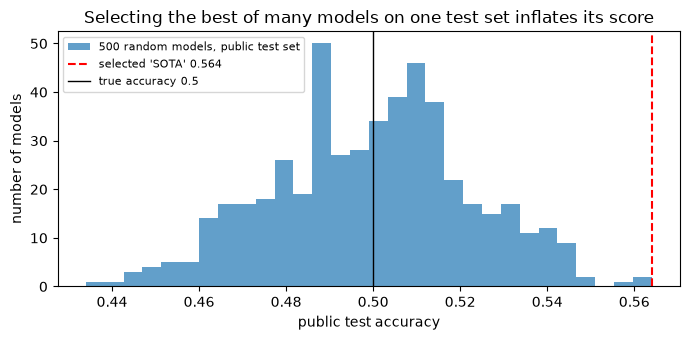

In [19]:
n_test, n_models = 500, 500
y_public = rng.integers(0, 2, n_test)
y_private = rng.integers(0, 2, n_test)                       # a fresh test set nobody has seen
preds_public = rng.integers(0, 2, (n_models, n_test))        # each "model" is a random guesser
preds_private = rng.integers(0, 2, (n_models, n_test))
acc_public = (preds_public == y_public).mean(1)
acc_private = (preds_private == y_private).mean(1)
best = acc_public.argmax()                                   # "SOTA" = best on the public leaderboard
print(f"best public-leaderboard accuracy: {acc_public[best]:.3f}  (true accuracy 0.500)")
print(f"the same model on a fresh test set: {acc_private[best]:.3f}")
print(f"models above 0.53 on the public set by luck alone: {(acc_public > 0.53).sum()} of {n_models}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(acc_public, bins=30, alpha=0.7, label="500 random models, public test set")
ax.axvline(acc_public[best], color="red", ls="--", label=f"selected 'SOTA' {acc_public[best]:.3f}")
ax.axvline(0.5, color="black", lw=1, label="true accuracy 0.5")
ax.set_xlabel("public test accuracy"); ax.set_ylabel("number of models")
ax.set_title("Selecting the best of many models on one test set inflates its score")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?** The "best" of 500 random guessers scored **0.564** on the public test set, a 6.4-point "improvement" over chance, and **0.534** on a fresh test set (itself a noisy estimate: with 500 examples the standard error of an accuracy near 0.5 is about 0.022, so 0.534 is consistent with the true 0.5). 43 models beat 0.53 by luck alone. Real benchmarks are less extreme because real models are correlated and genuinely better, but replication studies (e.g. Recht et al., 2019, rebuilding CIFAR-10 and ImageNet test sets) still found accuracy drops of several points, and leaderboards for LLMs have the extra problem of **test-set contamination** in pre-training data.

**Mitigations:** keep a private or held-out test set and use it rarely, report results on several benchmarks, use newly collected (post-training-cutoff) test sets, and correct for the number of comparisons.

### 5.2 Dataset shift

**Dataset shift** means the test (deployment) distribution differs from the training distribution. **Covariate shift**: P(x) changes but P(y | x) stays; **label (prior) shift**: P(y) changes; **concept drift**: P(y | x) itself changes. A model can be excellent in-distribution and poor after a shift, which an i.i.d. test set will never show.

In [20]:
def make_parabola(n, x1_low, x1_high, rng):
    x1 = rng.uniform(x1_low, x1_high, n)
    x2 = rng.uniform(-1, 9, n)
    y = (x2 > x1 ** 2).astype(int)                                 # the true rule: above the parabola
    return np.c_[x1, x2], y

X_in, y_in = make_parabola(2000, -1, 1, rng)                       # training region: x1 in [-1, 1]
X_iid, y_iid = make_parabola(1000, -1, 1, rng)                     # i.i.d. test set
X_shift, y_shift = make_parabola(1000, 1, 3, rng)                  # shifted test set: x1 in [1, 3]
linear = LogisticRegression().fit(X_in, y_in)
print(f"i.i.d. test accuracy:   {linear.score(X_iid, y_iid):.3f}")
print(f"shifted test accuracy:  {linear.score(X_shift, y_shift):.3f}  (covariate shift: P(x) moved, the rule did not)")

i.i.d. test accuracy:   0.975
shifted test accuracy:  0.629  (covariate shift: P(x) moved, the rule did not)


**What just happened?** A linear model learned the boundary well where it had data (0.975 i.i.d.), but when inputs moved to a region it never saw, accuracy fell to 0.629 even though the labelling rule did not change. In a thesis, an **out-of-distribution** test (another dataset, domain, time period or dialect) is the most direct evidence of external validity.

## 6. Pre-registration, analysis plans and human evaluation

> **In plain English:** Write your plan down before you see the results, and check that human judges agree.

### 6.1 Pre-registration and the analysis plan

**Pre-registration** means writing down your hypotheses, data, metrics and analysis *before* seeing the results, and time-stamping it (e.g. on OSF, AsPredicted, or as a dated commit in your repository; some ML venues and workshops accept **registered reports**, peer-reviewed before the experiments are run). It protects you from the garden of forking paths: trying many analyses and reporting the one that "worked" (notebook 3, Section 8).

A minimal **statistical analysis plan** answers:

| Item | Example |
|---|---|
| primary hypothesis | H1: M has higher macro-F1 than the strongest baseline on the test split |
| primary metric | macro-F1 (secondary: accuracy, calibration error, latency) |
| data and splits | fixed test split (n = 4,000), dev set for tuning; seeds 0–4 |
| comparison and test | paired bootstrap 95% CI on the test set; corrected resampled t-test on dev CV |
| α and correction | α = 0.05; Holm correction across the 3 secondary hypotheses |
| smallest effect of interest | 1 point macro-F1 (power analysis: n = 4,000 gives ≈ 80% power) |
| stopping and exclusions | no early stopping on test; runs that crash are re-run with the same seed and reported |
| what counts as "no effect" | 95% CI entirely within ±1 point (ROPE, notebook 3) |

### 6.2 Human evaluation design

Automatic metrics often miss what users care about (fluency, factuality, helpfulness, harm). A credible human evaluation needs:

1. **Clear guidelines** with definitions and worked examples for every label; a pilot round to fix ambiguities.
2. **Multiple annotators per item** (≥ 2, often 3) who are **blind** to which system produced the output, with outputs shown in **random order**.
3. **Enough items** (power analysis again) and a description of who the annotators are, how they were trained and how much they were paid; ethics approval when needed.
4. **Inter-annotator agreement** reported (below), and a plan for disagreements (majority vote, adjudication).
5. Prefer **pairwise preference** or fine-grained rubrics over vague 1–10 scores; include attention-check items.

### 6.3 Cohen's kappa (two annotators)

Raw agreement is misleading: two annotators who both say "correct" 90% of the time agree a lot *by chance*. **Cohen's kappa** corrects for chance:

$$\kappa = \frac{p_o - p_e}{1 - p_e}, \qquad p_e = \sum_{c} p_{1}(c)\, p_{2}(c)$$

where p_o is the observed agreement and p_e the agreement expected if both annotators labelled at random with their own label frequencies.

**Worked example by hand** (2 annotators, 50 items, labels yes/no):

| | B: yes | B: no | total |
|---|---|---|---|
| **A: yes** | 20 | 5 | 25 |
| **A: no** | 10 | 15 | 25 |
| **total** | 30 | 20 | 50 |

p_o = (20 + 15)/50 = 0.70; p_e = (25/50)(30/50) + (25/50)(20/50) = 0.30 + 0.20 = 0.50; κ = (0.70 − 0.50)/(1 − 0.50) = **0.40**.

In [21]:
def cohen_kappa(a, b, weights=None):
    # a, b: label sequences from two annotators. weights: None (nominal), 'linear' or 'quadratic' (ordinal labels)
    labels = sorted(set(a) | set(b))
    idx = {l: i for i, l in enumerate(labels)}
    k = len(labels)
    O = np.zeros((k, k))
    for x, y in zip(a, b):
        O[idx[x], idx[y]] += 1                                    # confusion matrix of the two annotators
    O /= O.sum()                                                  # observed proportions
    E = np.outer(O.sum(1), O.sum(0))                              # expected proportions under independence
    i, j = np.indices((k, k))
    if weights is None:
        W = (i != j).astype(float)                                # disagreement weight: 0 on diagonal, 1 elsewhere
    elif weights == "linear":
        W = np.abs(i - j) / (k - 1)
    else:
        W = ((i - j) / (k - 1)) ** 2
    return 1 - (W * O).sum() / (W * E).sum()                      # = (p_o - p_e) / (1 - p_e) for nominal

# The hand example: 20 yes/yes, 5 yes/no, 10 no/yes, 15 no/no
A = ["yes"] * 25 + ["no"] * 25
B = ["yes"] * 20 + ["no"] * 5 + ["yes"] * 10 + ["no"] * 15
print(f"hand example: kappa = {cohen_kappa(A, B):.3f}")

# Simulated LLM-answer ratings: 3 ordered labels, annotators agree ~75% of the time
labels = np.array(["wrong", "partial", "correct"])
true = rng.choice(3, size=200, p=[0.2, 0.3, 0.5])
noisy = lambda t: np.where(rng.random(t.size) < 0.8, t, np.clip(t + rng.choice([-1, 1], t.size), 0, 2))
ann1, ann2 = noisy(true), noisy(true)
print(f"raw agreement: {(ann1 == ann2).mean():.3f}")
for w in [None, "linear", "quadratic"]:
    ours, sk = cohen_kappa(ann1, ann2, w), cohen_kappa_score(ann1, ann2, weights=w)
    assert np.isclose(ours, sk), (w, ours, sk)                   # must match scikit-learn
    print(f"kappa ({w or 'unweighted'}): ours {ours:.4f} | sklearn {sk:.4f}")

hand example: kappa = 0.400
raw agreement: 0.745
kappa (unweighted): ours 0.5925 | sklearn 0.5925
kappa (linear): ours 0.6963 | sklearn 0.6963
kappa (quadratic): ours 0.7949 | sklearn 0.7949


**What just happened?** Our implementation reproduces the hand calculation (κ = 0.400) and matches scikit-learn exactly for unweighted, linear- and quadratic-weighted kappa. On the simulated ratings raw agreement is 0.745 but κ is only 0.593, because some agreement is expected by chance. The **weighted** kappas (0.696 linear, 0.795 quadratic) are higher because most disagreements are between *neighbouring* labels (partial vs correct), which ordinal weights penalise less.

**Complexity:** O(n + k²) for n items and k labels.

### 6.4 Krippendorff's alpha (any number of annotators, missing data, any scale)

Kappa handles two annotators with complete data. **Krippendorff's alpha** handles any number of annotators, **missing ratings**, and nominal, ordinal, interval or ratio scales:

$$\alpha = 1 - \frac{D_o}{D_e}$$

where D_o is the observed disagreement *within* items and D_e the disagreement expected by chance (pairing all values regardless of item). Steps: build the **coincidence matrix** o_{ck} (each pair of values within an item with m ratings adds 1/(m−1)), compute the marginals n_c, then

$$\alpha = 1 - (n - 1)\frac{\sum_{c,k} o_{ck}\, \delta^2_{ck}}{\sum_{c,k} n_c n_k\, \delta^2_{ck}}$$

with a difference function δ² that depends on the scale (nominal: 0/1; interval: (c − k)²; ordinal and ratio have their own formulas). We verify the implementation on the worked example in Krippendorff (2011), *Computing Krippendorff's Alpha-Reliability*: 4 observers, 12 units, with missing values; published results **nominal 0.743, ordinal 0.815, interval 0.849, ratio 0.797**.

In [22]:
from itertools import permutations

def krippendorff_alpha(data, level="nominal"):
    # data: observers x units array, np.nan = missing rating
    data = np.asarray(data, dtype=float)
    units = [col[~np.isnan(col)] for col in data.T]
    units = [u for u in units if len(u) >= 2]                    # only units with >= 2 ratings are pairable
    values = np.array(sorted(set(np.concatenate(units))))
    idx = {v: i for i, v in enumerate(values)}
    V = len(values)
    o = np.zeros((V, V))                                         # coincidence matrix
    for u in units:
        m = len(u)
        for a, b in permutations(range(m), 2):                   # every ordered pair of ratings within the unit
            o[idx[u[a]], idx[u[b]]] += 1.0 / (m - 1)
    n_c = o.sum(1); n = n_c.sum()                                # marginals and total number of pairable values
    c, k = np.meshgrid(values, values, indexing="ij")
    if level == "nominal":
        d2 = (c != k).astype(float)
    elif level == "interval":
        d2 = (c - k) ** 2
    elif level == "ratio":
        d2 = ((c - k) / (c + k)) ** 2
    elif level == "ordinal":                                     # uses the marginal counts between the two ranks
        d2 = np.zeros((V, V))
        for i in range(V):
            for j in range(V):
                lo, hi = min(i, j), max(i, j)
                d2[i, j] = (n_c[lo:hi + 1].sum() - (n_c[lo] + n_c[hi]) / 2) ** 2
    else:
        raise ValueError(level)
    D_o = (o * d2).sum()
    D_e = (np.outer(n_c, n_c) * d2).sum() / (n - 1)
    return 1 - D_o / D_e

nan = np.nan
reliability_data = [                         # Krippendorff (2011), observers A-D x units 1-12
    [1, 2, 3, 3, 2, 1, 4, 1, 2, nan, nan, nan],
    [1, 2, 3, 3, 2, 2, 4, 1, 2, 5, nan, 3],
    [nan, 3, 3, 3, 2, 3, 4, 2, 2, 5, 1, nan],
    [1, 2, 3, 3, 2, 4, 4, 1, 2, 5, 1, nan],
]
published = {"nominal": 0.743, "ordinal": 0.815, "interval": 0.849, "ratio": 0.797}
for level, ref in published.items():
    a = krippendorff_alpha(reliability_data, level)
    assert round(a, 3) == ref, (level, a)
    print(f"{level:<9} alpha = {a:.4f}  (published {ref})")

# Sanity checks: perfect agreement -> 1; and on our two-annotator LLM ratings alpha is close to kappa
assert np.isclose(krippendorff_alpha([[1, 2, 3, 1], [1, 2, 3, 1]]), 1.0)
alpha_llm = krippendorff_alpha(np.vstack([ann1, ann2]), "nominal")
alpha_llm_ord = krippendorff_alpha(np.vstack([ann1, ann2]), "ordinal")
print(f"\nLLM ratings (2 annotators): nominal alpha {alpha_llm:.4f} vs Cohen's kappa {cohen_kappa(ann1, ann2):.4f}; ordinal alpha {alpha_llm_ord:.4f}")

nominal   alpha = 0.7434  (published 0.743)
ordinal   alpha = 0.8154  (published 0.815)
interval  alpha = 0.8491  (published 0.849)
ratio     alpha = 0.7974  (published 0.797)



LLM ratings (2 annotators): nominal alpha 0.5925 vs Cohen's kappa 0.5925; ordinal alpha 0.7622


**What just happened?** Our from-scratch alpha reproduces all four published values (0.743, 0.815, 0.849, 0.797) on data with missing ratings and up to 4 observers per unit. On the two-annotator LLM ratings, nominal alpha equals kappa to four decimals here (0.5925). In general they differ slightly, because alpha estimates chance agreement from the *pooled* label distribution of both annotators and includes a small-sample correction, while kappa uses each annotator's own distribution; with similar label distributions and 200 items the two effects cancel almost exactly. Treating the labels as ordinal gives alpha = 0.762.

**How to read agreement values** (rules of thumb, not laws): Krippendorff recommends α ≥ 0.80 for reliable data and 0.667 ≤ α < 0.80 only for tentative conclusions; Landis & Koch (1977) call κ of 0.41–0.60 "moderate" and 0.61–0.80 "substantial". Our nominal 0.59 ("moderate") and ordinal 0.76 ("tentative") mean the guidelines need another round before the annotations are used for evaluation.

**Complexity:** O(Σ m_u²) for the pairs within units plus O(V²) for the matrices (V distinct values); the ordinal distance as written is O(V³), fine for the handful of labels used in practice.

> ⚠️ **Common mistake:** reporting only percentage agreement, or computing kappa on labels from three or more annotators by averaging pairs without saying so. Report the coefficient, the scale (nominal/ordinal), the number of annotators and items, and how disagreements were resolved.

## 7. An experiment-plan template

> **In plain English:** One form to fill in before you run anything.

Fill this in **before** running the main experiments (it doubles as your pre-registration and as the methods section of the thesis). Below it is stored as YAML, written to a temporary file, read back and checked for missing fields, the way a lab could keep plans next to the code.

```yaml
title:            <one line>
research_question: <the RQ, FINER-checked>
hypotheses:       {H0: ..., H1: ...}
independent_variables: [method, ...]
dependent_variables:   {primary: ..., secondary: [...]}
controlled_variables:  [splits, tuning budget, epochs, hardware, preprocessing]
data:             {source: ..., licence: ..., n_train: ..., n_test: ..., split: ..., groups_or_time: ...}
baselines:        [trivial, classical, prior SOTA re-run]
ablations:        [...]
tuning:           {method: random search, budget_per_method: ..., search_spaces: ...}
seeds:            [0, 1, 2, 3, 4]
power_analysis:   {smallest_effect: ..., n_test: ..., power: ...}
statistical_analysis: {test: ..., alpha: 0.05, correction: Holm, effect_size: ...}
human_evaluation: {annotators: ..., items: ..., agreement: Krippendorff alpha, blinding: yes}
threats_to_validity: {internal: ..., external: ..., construct: ..., conclusion: ...}
compute_budget:   {gpu_hours: ...}
ethics:           {approval: ..., consent: ..., licence_check: ...}
```

In [23]:
plan = {
    "title": "Few-shot LLM prompting vs fine-tuned Urdu BERT for fake-news detection",
    "research_question": "Does few-shot prompting of an open 7B LLM reach the macro-F1 of a fine-tuned Urdu BERT on the Urdu news test split under equal GPU-hours?",
    "hypotheses": {"H0": "no difference in expected macro-F1", "H1": "the fine-tuned model has higher macro-F1"},
    "independent_variables": ["method (prompting vs fine-tuning)", "number of shots (0, 4, 16)"],
    "dependent_variables": {"primary": "macro-F1", "secondary": ["accuracy", "expected calibration error", "latency"]},
    "controlled_variables": ["same test split", "same preprocessing", "equal GPU-hour budget", "same hardware"],
    "data": {"source": "own collection (fictional)", "licence": "CC BY-NC 4.0", "n_train": 4000, "n_test": 4000,
             "split": "by news outlet (GroupKFold) and by date"},
    "baselines": ["majority class", "TF-IDF + logistic regression", "XLM-R fine-tuned (prior SOTA re-run)"],
    "ablations": ["- domain-adaptive pre-training", "- label-description prompt", "only headline vs full text"],
    "tuning": {"method": "random search", "budget_per_method": "30 trials or 20 GPU-hours"},
    "seeds": [0, 1, 2, 3, 4],
    "power_analysis": {"smallest_effect": "1 point macro-F1", "n_test": 4000, "power": 0.8},
    "statistical_analysis": {"test": "paired bootstrap CI + McNemar", "alpha": 0.05, "correction": "Holm", "effect_size": "difference in macro-F1 with 95% CI"},
    "human_evaluation": {"annotators": 3, "items": 300, "agreement": "Krippendorff alpha (nominal)", "blinding": True},
    "threats_to_validity": {"internal": "prompt sensitivity", "external": "one language, news domain only",
                            "construct": "macro-F1 vs real newsroom usefulness", "conclusion": "5 seeds only"},
    "ethics": {"approval": "pending (university REC)", "consent": "public articles, no personal data", "licence_check": True},
}
REQUIRED_KEYS = ["title", "research_question", "hypotheses", "independent_variables", "dependent_variables",
                 "controlled_variables", "data", "baselines", "ablations", "tuning", "seeds", "power_analysis",
                 "statistical_analysis", "human_evaluation", "threats_to_validity", "compute_budget", "ethics"]

workdir = Path(tempfile.mkdtemp())
plan_file = workdir / "experiment_plan.yaml"
plan_file.write_text(yaml.safe_dump(plan, sort_keys=False, allow_unicode=True), encoding="utf-8")
loaded = yaml.safe_load(plan_file.read_text(encoding="utf-8"))
missing = [k for k in REQUIRED_KEYS if k not in loaded]
print(plan_file.read_text(encoding="utf-8")[:600], "...")
print("missing fields:", missing)
shutil.rmtree(workdir)

title: Few-shot LLM prompting vs fine-tuned Urdu BERT for fake-news detection
research_question: Does few-shot prompting of an open 7B LLM reach the macro-F1 of
  a fine-tuned Urdu BERT on the Urdu news test split under equal GPU-hours?
hypotheses:
  H0: no difference in expected macro-F1
  H1: the fine-tuned model has higher macro-F1
independent_variables:
- method (prompting vs fine-tuning)
- number of shots (0, 4, 16)
dependent_variables:
  primary: macro-F1
  secondary:
  - accuracy
  - expected calibration error
  - latency
controlled_variables:
- same test split
- same preprocessing
- eq ...
missing fields: ['compute_budget']


**What just happened?** The plan was saved as YAML and read back, and the checker found one missing field: **compute_budget**. That omission matters, because "equal GPU-hours" is one of the controlled variables. Adding `"compute_budget": {"gpu_hours": 40}` fixes it. Keeping the plan as a file in the repository (with its commit date) makes it a lightweight pre-registration.

## 8. 🔗 How this connects to modern AI

> **In plain English:** LLM evaluations, leaderboards and A/B tests are all experiments with the same rules.

- **LLM evaluation** is experiment design: prompts, decoding temperature and few-shot examples are factors (factorial designs reveal prompt × model interactions); seeds and sampling make outputs random; benchmark contamination is a threat to validity; LLM-as-judge needs agreement checks against humans (kappa/alpha). See [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb).
- **Leaderboards** such as LMArena use pairwise human preferences and report confidence intervals: the same blinding, randomisation and power ideas as Sections 4 and 6.
- **Scaling laws** are learning curves in data, parameters and compute (Section 3.7).
- **Ablations** are how papers such as the original Transformer paper justified each component; for RAG and agent systems, ablate retriever, re-ranker, prompt and tools one at a time.
- **Industry A/B tests** are randomised controlled experiments with power analysis: [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb) and its [industry report](../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb). **Experiment tracking** tools ([MLflow](../15_MLOps/01_experiment_tracking/01_mlflow.ipynb)) record seeds, configs and budgets so ablation tables can be regenerated.

## Recap

- Name your **independent, dependent, controlled** variables and look for **confounders**; randomisation makes comparisons causal (Simpson's paradox shows what happens without it).
- **Block** on the data split (evaluate all models on the same folds, analyse paired differences); use **factorial designs** to see interactions.
- Keep a locked **test set**; use **nested CV** for honest tuning estimates; split by **group** and by **time** when rows are not independent.
- Beat **trivial, classical and re-run SOTA baselines**; give every method the **same tuning budget**.
- Run **ablations** ("−X" and "only X" when components overlap) and present them as a table.
- Report **multiple seeds**; a single run is one sample. Use **learning curves** to see if data size changes conclusions.
- Avoid **leakage**: everything that learns from data goes inside the pipeline.
- **Power analysis:** detecting a 1-point accuracy difference needs ≈ 19,500 examples per model with independent samples, or ≈ 3,900 on a shared test set when the models disagree on 5% of items.
- Consider all four **threats to validity**; beware of benchmark overfitting and dataset shift.
- **Pre-register** the analysis plan; design human evaluation with guidelines, blinding and agreement (**kappa**, **Krippendorff's alpha**).

## Practice problems

**1. (Easy)** In the study "Does adding back-translated data improve Urdu sentiment F1 for XLM-R?", name the independent, dependent and two controlled variables, and one possible confounder.

<details><summary>Show solution</summary>

IV: augmentation (with / without back-translated data). DV: F1 on the test set. Controlled: same test split, same number of training steps (or epochs adjusted for data size!), same hyper-parameter budget, same seeds. Possible confounder: *more training steps* (augmented runs see more batches), or the back-translated data accidentally containing test sentences (leakage). Control them by fixing the number of steps and de-duplicating.
</details>

**2. (Easy, coding)** Compute Cohen's kappa by hand and with `cohen_kappa` for: A = [1,1,1,0,0,0,1,1,0,1], B = [1,1,0,0,0,1,1,1,0,1].

<details><summary>Show solution</summary>

Agreement on 8 of 10 → p_o = 0.8. A has six 1s, B has six 1s → p_e = 0.6·0.6 + 0.4·0.4 = 0.52. κ = (0.8 − 0.52)/(1 − 0.52) = 0.583.
```python
A = [1,1,1,0,0,0,1,1,0,1]; B = [1,1,0,0,0,1,1,1,0,1]
print(round(cohen_kappa(A, B), 3))   # 0.583
```
</details>

**3. (Medium, coding)** Using `n_paired_mcnemar`, how many shared test examples are needed to detect a **2-point** difference when models disagree on 10% of items? What about 1 point?

<details><summary>Show solution</summary>

```python
print(n_paired_mcnemar(0.02, 0.10), n_paired_mcnemar(0.01, 0.10))   # 1960 and 7847
```
Halving the effect size roughly **quadruples** the required n, because n ∝ 1/δ².
</details>

**4. (Medium, conceptual)** A paper reports 92.4% (theirs) vs 91.8% (baseline) on a 1,000-example test set, single run each, baseline numbers copied from an older paper. List at least four problems.

<details><summary>Show solution</summary>

(1) Single run: seed variance (often ±0.5–2 points) is larger than the 0.6-point gap. (2) Underpowered: with 1,000 examples the MDE is around 2 points (Section 4). (3) Copied baseline = observational comparison with different preprocessing/splits/tuning (internal validity). (4) No significance test or CI. (5) Possibly unequal tuning budget. (6) One test set: possible benchmark overfitting; no evidence of external validity.
</details>

**5. (Medium, coding)** Repeat the leakage experiment with `k=200` selected features. Does the leaky estimate go up or down? Why?

<details><summary>Show solution</summary>

```python
X_sel200 = SelectKBest(f_classif, k=200).fit_transform(X_noise, y_noise)
print(cross_val_score(LogisticRegression(max_iter=1000), X_sel200, y_noise, cv=cv_noise).mean())  # 0.97
```
It goes **up** to 0.97: with 200 features chosen using all labels, a linear model can almost perfectly separate 100 points, and every chosen feature carries a little leaked label information. The correct pipeline stays near 0.5 whatever k is.
</details>

**6. (Hard, coding)** Write `ablation_table(configs, model_fn, X, y, cv)` that returns a DataFrame with the mean, std and paired Δ vs the first configuration, and test it on two of the configurations above.

<details><summary>Show solution</summary>

```python
def ablation_table(configs, model_fn, X, y, cv):
    scores = {n: cross_val_score(model_fn(k), X, y, cv=cv) for n, k in configs.items()}
    ref = next(iter(scores.values()))
    return pd.DataFrame({"mean": {n: s.mean() for n, s in scores.items()},
                         "std": {n: s.std(ddof=1) for n, s in scores.items()},
                         "delta": {n: (s - ref).mean() for n, s in scores.items()}})

t = ablation_table({"full": ["mean", "error", "worst"], "- worst": ["mean", "error"]}, make_model, X_bc, y_bc, cv_abl)
assert t.loc["full", "delta"] == 0 and t.loc["- worst", "delta"] < 0
```
</details>

**7. (Hard, design)** You must compare 3 prompting strategies × 2 LLMs × 2 temperatures with human judges. Sketch the design: factors, blocking, randomisation, agreement and analysis.

<details><summary>Show solution</summary>

A 3 × 2 × 2 full factorial (12 conditions). **Block** on the input item: every item is answered under all 12 conditions, so comparisons are within-item (paired). **Randomise** the order in which outputs are shown and hide the condition (blinding); give each output to 3 judges, balanced so each judge sees all conditions. Pilot the guidelines until Krippendorff's α ≥ 0.667 (ideally ≥ 0.8). Analyse main effects and interactions (e.g. a mixed-effects model with item and judge as random effects, or paired bootstrap per contrast), correct for multiple comparisons, and pre-register the primary contrast. Use power analysis on pilot data to choose the number of items.
</details>

In [24]:
# Verify the practice-problem code solutions
A2 = [1, 1, 1, 0, 0, 0, 1, 1, 0, 1]; B2 = [1, 1, 0, 0, 0, 1, 1, 1, 0, 1]
assert round(cohen_kappa(A2, B2), 3) == 0.583 and np.isclose(cohen_kappa(A2, B2), cohen_kappa_score(A2, B2))
assert (n_paired_mcnemar(0.02, 0.10), n_paired_mcnemar(0.01, 0.10)) == (1960, 7847), (n_paired_mcnemar(0.02, 0.10), n_paired_mcnemar(0.01, 0.10))
X_sel200 = SelectKBest(f_classif, k=200).fit_transform(X_noise, y_noise)
leak200 = cross_val_score(LogisticRegression(max_iter=1000), X_sel200, y_noise, cv=cv_noise).mean()
assert leak200 > wrong and round(leak200, 2) == 0.97, leak200

def ablation_table(configs, model_fn, X, y, cv):
    scores = {n: cross_val_score(model_fn(k), X, y, cv=cv) for n, k in configs.items()}
    ref = next(iter(scores.values()))
    return pd.DataFrame({"mean": {n: s.mean() for n, s in scores.items()},
                         "std": {n: s.std(ddof=1) for n, s in scores.items()},
                         "delta": {n: (s - ref).mean() for n, s in scores.items()}})
t = ablation_table({"full": ["mean", "error", "worst"], "- worst": ["mean", "error"]}, make_model, X_bc, y_bc, cv_abl)
assert t.loc["full", "delta"] == 0 and t.loc["- worst", "delta"] < 0
print("practice solutions verified; leaky accuracy with k=200:", round(leak200, 3))
print(t.round(4))
print(f"total notebook runtime so far: {time.time() - T0:.0f} s")

practice solutions verified; leaky accuracy with k=200: 0.97
           mean     std   delta
full     0.9772  0.0148  0.0000
- worst  0.9539  0.0212 -0.0232
total notebook runtime so far: 176 s


## Further reading

- D. C. Montgomery, *Design and Analysis of Experiments*, 10th ed., Wiley: randomisation, blocking, factorial designs (chapters 1–6).
- G. E. P. Box, J. S. Hunter & W. G. Hunter, *Statistics for Experimenters*, 2nd ed., 2005.
- W. Shadish, T. Cook & D. Campbell, *Experimental and Quasi-Experimental Designs for Generalized Causal Inference*, 2002: the four validity types.
- S. Raschka, "Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning", arXiv:1811.12808 (free): nested CV, tests, practical advice.
- J. Pineau et al., "Improving Reproducibility in Machine Learning Research", *JMLR* 2021, and the NeurIPS paper checklist.
- B. Recht et al., "Do ImageNet Classifiers Generalize to ImageNet?", ICML 2019 (test-set reuse).
- K. Krippendorff, *Content Analysis*, 4th ed., 2018, and "Computing Krippendorff's Alpha-Reliability" (2011, free PDF).
- Free online: scikit-learn user guide, "Cross-validation: evaluating estimator performance" and "Common pitfalls and recommended practices".

## Next notebook

➡️ [03 – Statistical significance and reporting](03_statistical_significance_and_reporting.ipynb): decide whether your improvement is real and report it honestly.